In [1]:
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import os
import sklearn, matplotlib
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset

In [2]:
PROYECTO = ".."   # raíz del repo (el notebook está en notebooks/)

req_content = f"""torch=={torch.__version__.split('+')[0]}
scikit-learn=={sklearn.__version__}
numpy=={np.__version__}
matplotlib=={matplotlib.__version__}
"""
with open(f"{PROYECTO}/requirements.txt", "w", encoding="utf-8") as f:
    f.write(req_content)

print("requirements.txt guardado en:", os.path.abspath(f"{PROYECTO}/requirements.txt"))
print(req_content)

requirements.txt guardado en: c:\Users\Usuario\Documents\pipeline-dl-base\requirements.txt
torch==2.15.0
scikit-learn==1.9.1
numpy==2.5.4
matplotlib==3.11.2



In [3]:
SEED = 42

def fijar_semillas(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def detectar_dispositivo() -> torch.device:
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

fijar_semillas(SEED)
device = detectar_dispositivo()

print("PyTorch:", torch.__version__)
print("Dispositivo:", device)
print("Semilla:", SEED)

PyTorch: 2.15.0+cpu
Dispositivo: cpu
Semilla: 42


In [4]:
iris = load_iris()
X, y = iris.data, iris.target

print("X:", X.shape, "| y:", y.shape)
print("Clases:", iris.target_names)

N_FEATURES = X.shape[1]
N_CLASSES = len(np.unique(y))
print("Entradas:", N_FEATURES, "| Clases:", N_CLASSES)

X: (150, 4) | y: (150,)
Clases: ['setosa' 'versicolor' 'virginica']
Entradas: 4 | Clases: 3


In [5]:
class ClasificadorBase(nn.Module):
    def __init__(self, in_features: int, hidden: int, n_classes: int):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Linear(hidden, n_classes),  # logits crudos para CrossEntropyLoss
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)

In [6]:
HIDDEN = 16

model = ClasificadorBase(N_FEATURES, HIDDEN, N_CLASSES).to(device)
print(model)

x_prueba = torch.randn(8, N_FEATURES).to(device)
salida = model(x_prueba)
print("Entrada:", tuple(x_prueba.shape), "-> Salida:", tuple(salida.shape))
assert salida.shape == (8, N_CLASSES)

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Parámetros entrenables:", n_params)

ClasificadorBase(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=3, bias=True)
  )
)


Entrada: (8, 4) -> Salida: (8, 3)
Parámetros entrenables: 403


In [7]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

# El scaler se ajusta SOLO con train, para evitar data leakage
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)

X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.long)
X_val_t = torch.tensor(X_val, dtype=torch.float32)
y_val_t = torch.tensor(y_val, dtype=torch.long)

train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=16, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val_t, y_val_t), batch_size=16, shuffle=False)

In [8]:
LEARNING_RATE = 1e-2
EPOCHS = 100

model = ClasificadorBase(N_FEATURES, HIDDEN, N_CLASSES).to(device)
criterion = nn.CrossEntropyLoss() 
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

In [9]:
def entrenar_una_epoca(model, loader, criterion, optimizer, device):
    model.train()
    loss_total, correctas, total = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)

        logits = model(xb)               # forward
        loss = criterion(logits, yb)     # pérdida

        optimizer.zero_grad()            # reinicia gradientes acumulados
        loss.backward()                  # backward (autograd)
        optimizer.step()                 # actualiza pesos

        loss_total += loss.item() * xb.size(0)
        correctas += (logits.argmax(dim=1) == yb).sum().item()
        total += xb.size(0)
    return loss_total / total, correctas / total


@torch.no_grad()
def evaluar(model, loader, criterion, device):
    model.eval()
    loss_total, correctas, total = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        loss_total += criterion(logits, yb).item() * xb.size(0)
        correctas += (logits.argmax(dim=1) == yb).sum().item()
        total += xb.size(0)
    return loss_total / total, correctas / total

In [10]:
historial = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

for epoca in range(1, EPOCHS + 1):
    tr_loss, tr_acc = entrenar_una_epoca(model, train_loader, criterion, optimizer, device)
    va_loss, va_acc = evaluar(model, val_loader, criterion, device)

    historial["train_loss"].append(tr_loss)
    historial["val_loss"].append(va_loss)
    historial["train_acc"].append(tr_acc)
    historial["val_acc"].append(va_acc)

    if epoca == 1 or epoca % 10 == 0:
        print(f"Época {epoca:3d} | train loss {tr_loss:.4f} acc {tr_acc:.3f} "
              f"| val loss {va_loss:.4f} acc {va_acc:.3f}")

Época   1 | train loss 0.9609 acc 0.667 | val loss 0.7992 acc 0.767
Época  10 | train loss 0.0863 acc 0.975 | val loss 0.0807 acc 0.967
Época  20 | train loss 0.0490 acc 0.975 | val loss 0.0490 acc 1.000
Época  30 | train loss 0.0408 acc 0.975 | val loss 0.0551 acc 1.000
Época  40 | train loss 0.0414 acc 0.975 | val loss 0.0554 acc 0.967
Época  50 | train loss 0.0407 acc 0.992 | val loss 0.0576 acc 0.967
Época  60 | train loss 0.0384 acc 0.975 | val loss 0.0478 acc 0.967
Época  70 | train loss 0.0419 acc 0.983 | val loss 0.0535 acc 0.967
Época  80 | train loss 0.0375 acc 0.983 | val loss 0.0523 acc 0.967
Época  90 | train loss 0.0396 acc 0.983 | val loss 0.0471 acc 0.967
Época 100 | train loss 0.0372 acc 0.983 | val loss 0.0507 acc 0.967


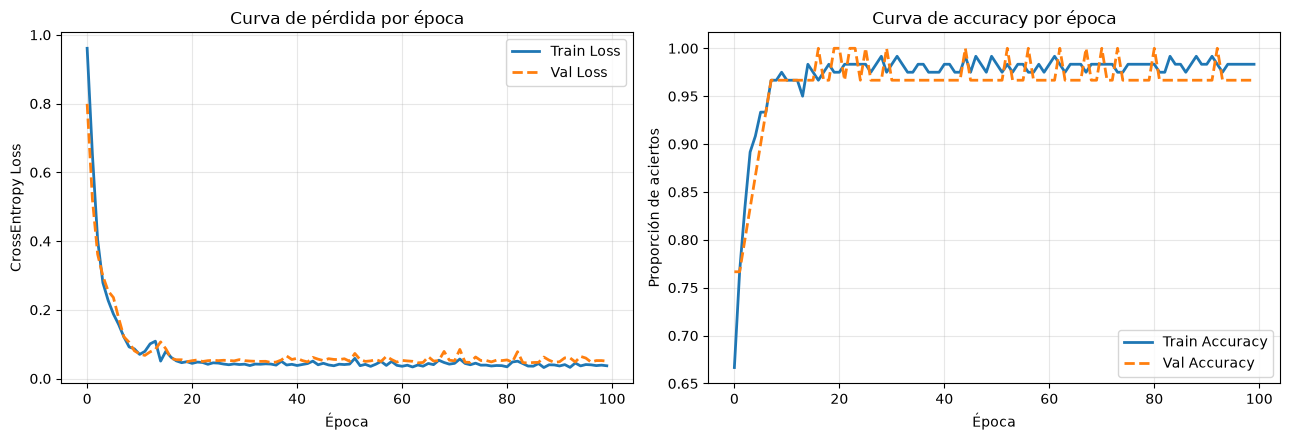

Versión de PyTorch: 2.15.0+cpu
Dispositivo: cpu
Learning rate: 0.01
Épocas: 100
Pérdida inicial (época 1): train 0.9609 | val 0.7992
Pérdida final (época 100): train 0.0372 | val 0.0507
Accuracy final en validación: 96.67%


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(historial["train_loss"], label="Train Loss", lw=2)
axes[0].plot(historial["val_loss"], label="Val Loss", lw=2, linestyle="--")
axes[0].set_title("Curva de pérdida por época")
axes[0].set_xlabel("Época"); axes[0].set_ylabel("CrossEntropy Loss")
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(historial["train_acc"], label="Train Accuracy", lw=2)
axes[1].plot(historial["val_acc"], label="Val Accuracy", lw=2, linestyle="--")
axes[1].set_title("Curva de accuracy por época")
axes[1].set_xlabel("Época"); axes[1].set_ylabel("Proporción de aciertos")
axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
os.makedirs("../reports/figures", exist_ok=True)
plt.savefig("../reports/figures/loss_curve.png", dpi=150)
plt.show()

# Datos del experimento (se muestran acá y se documentan a mano en el README)
print("Versión de PyTorch:", torch.__version__)
print("Dispositivo:", device)
print("Learning rate:", LEARNING_RATE)
print("Épocas:", EPOCHS)
print(f"Pérdida inicial (época 1): train {historial['train_loss'][0]:.4f} | val {historial['val_loss'][0]:.4f}")
print(f"Pérdida final (época {EPOCHS}): train {historial['train_loss'][-1]:.4f} | val {historial['val_loss'][-1]:.4f}")
print(f"Accuracy final en validación: {historial['val_acc'][-1]*100:.2f}%")